# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [1]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [2]:
# Inspect the shapes of the datasets
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


In [5]:
# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical

y_train_onehot = to_categorical(y_train, num_classes=10)
y_test_onehot = to_categorical(y_test, num_classes=10)

print("Original label:", y_train[0])
print("One-hot label:", y_train_onehot[0])

Original label: 9
One-hot label: [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


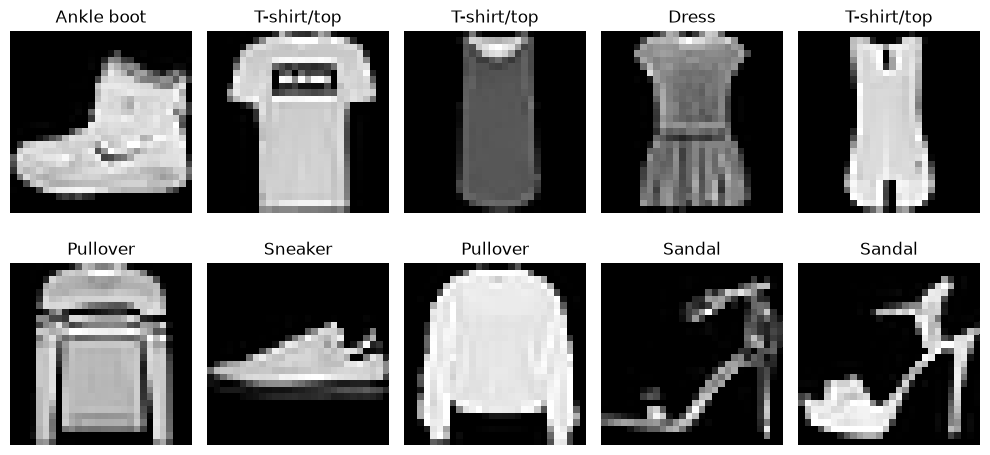

In [6]:
# lets display some images !
import matplotlib.pyplot as plt
# Verify the data looks as expected
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

**My Reflection :**
Yes, it look as expected, different images with reasonable labels. T-shirts and pullovers shapes similar, may make classification difficult. I would need to inspect more ! Overall, no big odd happening so far !

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

In [9]:
from keras.models import Sequential
from keras.layers import Input, Dense, Flatten
# Create a simple linear regression model
model = Sequential()
# You can use `model.add(<layer>)` to add layers to the model
model.add(Input(shape=(28, 28)))
model.add(Flatten())
model.add(Dense(10))
# Compile the model using `model.compile()`
model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["categorical_accuracy"]
)
# Train the model with `model.fit()`
history = model.fit(
    X_train,
    y_train_onehot,
    epochs=8,
    batch_size=128,
    validation_split=0.2
)
# Evaluate the model with `model.evaluate()`
baseline_loss, baseline_accuracy = model.evaluate(
    X_test,
    y_test_onehot
)

print("Baseline test loss:", round(baseline_loss, 4))
print(f"Baseline test accuracy: {baseline_accuracy:.2%}")

Epoch 1/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - categorical_accuracy: 0.6546 - loss: 0.0766 - val_categorical_accuracy: 0.7517 - val_loss: 0.0525
Epoch 2/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - categorical_accuracy: 0.7823 - loss: 0.0474 - val_categorical_accuracy: 0.7925 - val_loss: 0.0441
Epoch 3/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - categorical_accuracy: 0.8010 - loss: 0.0424 - val_categorical_accuracy: 0.7978 - val_loss: 0.0419
Epoch 4/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - categorical_accuracy: 0.8090 - loss: 0.0402 - val_categorical_accuracy: 0.8100 - val_loss: 0.0395
Epoch 5/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - categorical_accuracy: 0.8147 - loss: 0.0390 - val_categorical_accuracy: 0.8125 - val_loss: 0.0394
Epoch 6/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - categorical_accuracy: 0.8173 - loss: 0.0383 - val_categorical_accuracy: 0.8154 - val_loss: 0.0380
Epoch 7/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - categorical_accuracy: 0.8184 - loss: 0.03

Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

**My Reflection**
BL model test accuracy of 80% with test loss 0.0398, which means it correctly classified about 80% images in test data. As a simple model, I guess its good starting accuracy. 
Training and validation accuracy were close, means we could not see any large sign of overfitting.

# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

In [11]:
from keras.models import Sequential
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create a simple CNN model
model = Sequential()
model.add(Input(shape=(28, 28, 1)))
model.add(Conv2D(32, kernel_size=(3, 3), activation="relu"))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(64, activation="relu"))
model.add(Dense(10, activation="softmax"))

# Compile the model
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["categorical_accuracy"]
)

# Train the model
cnn_history = model.fit(
    X_train,
    y_train_onehot,
    epochs=8,
    batch_size=128,
    validation_split=0.2
)

# Evaluate the model
cnn_loss, cnn_accuracy = model.evaluate(
    X_test,
    y_test_onehot
)

print("CNN test loss:", round(cnn_loss, 4))
print(f"CNN test accuracy: {cnn_accuracy:.2%}")

# Compare with the baseline
difference = (cnn_accuracy - baseline_accuracy) * 100
print(f"Accuracy change from baseline: {difference:+.2f} percentage points")

Epoch 1/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - categorical_accuracy: 0.8210 - loss: 0.5184 - val_categorical_accuracy: 0.8615 - val_loss: 0.3914
Epoch 2/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - categorical_accuracy: 0.8784 - loss: 0.3455 - val_categorical_accuracy: 0.8837 - val_loss: 0.3295
Epoch 3/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - categorical_accuracy: 0.8946 - loss: 0.2991 - val_categorical_accuracy: 0.8939 - val_loss: 0.3017
Epoch 4/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - categorical_accuracy: 0.9044 - loss: 0.2684 - val_categorical_accuracy: 0.9019 - val_loss: 0.2763
Epoch 5/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - categorical_accuracy: 0.9119 - loss: 0.2474 - val_categorical_accuracy: 0.9043 - val_loss: 0.2699
Epoch 6/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - categorical_accuracy: 0.9170 - loss: 0.2315 - val_categorical_accuracy: 0.9074 - val_loss: 0.2603
Epoch 7/8
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - categorical_accuracy: 0.9243 - los

Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

**My Reflection:**
Yes, CNN performed better than BL, test accuracy was 89.87% instead of 80.09%, its 9.78% points increased in Accuracy. The convolutional layer helps model learn local patterns, which were useful for recognizing clothing. 

The hidden dense layer and classification loss also contributed to model ability to learn. Training accuracy continued to improve, but validation accuracy dropped a bit in last epoch, this could be overfitting sign, need to explore.

# 4. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

In [12]:
# A. Test Hyperparameters
import keras
import pandas as pd
import matplotlib.pyplot as plt

from keras.models import Sequential
from keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
)

filter_results = []

for filters in [16, 32, 64]:

    # Start with a new model for each experiment
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)

    model = Sequential()
    model.add(Input(shape=(28, 28, 1)))
    model.add(Conv2D(filters, kernel_size=(3, 3), activation="relu"))
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Flatten())
    model.add(Dense(64, activation="relu"))
    model.add(Dense(10, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["categorical_accuracy"]
    )

    print(f"\nTraining with {filters} filters")

    history = model.fit(
        X_train,
        y_train_onehot,
        epochs=8,
        batch_size=128,
        validation_split=0.2,
        verbose=2
    )

    test_loss, test_accuracy = model.evaluate(
        X_test, y_test_onehot, verbose=0
    )

    # Record the results after the final epoch
    filter_results.append({
        "Filters": filters,
        "Validation accuracy": history.history[
            "val_categorical_accuracy"
        ][-1],
        "Test accuracy": test_accuracy,
        "Test loss": test_loss
    })

filter_results = pd.DataFrame(filter_results)
print(filter_results.round(4))



Training with 16 filters
Epoch 1/8
375/375 - 3s - 7ms/step - categorical_accuracy: 0.8195 - loss: 0.5230 - val_categorical_accuracy: 0.8683 - val_loss: 0.3799
Epoch 2/8
375/375 - 2s - 6ms/step - categorical_accuracy: 0.8790 - loss: 0.3461 - val_categorical_accuracy: 0.8850 - val_loss: 0.3276
Epoch 3/8
375/375 - 2s - 6ms/step - categorical_accuracy: 0.8931 - loss: 0.3014 - val_categorical_accuracy: 0.8900 - val_loss: 0.3042
Epoch 4/8
375/375 - 2s - 6ms/step - categorical_accuracy: 0.9024 - loss: 0.2730 - val_categorical_accuracy: 0.8961 - val_loss: 0.2883
Epoch 5/8
375/375 - 2s - 6ms/step - categorical_accuracy: 0.9104 - loss: 0.2514 - val_categorical_accuracy: 0.8991 - val_loss: 0.2787
Epoch 6/8
375/375 - 2s - 6ms/step - categorical_accuracy: 0.9162 - loss: 0.2332 - val_categorical_accuracy: 0.9014 - val_loss: 0.2718
Epoch 7/8
375/375 - 2s - 6ms/step - categorical_accuracy: 0.9215 - loss: 0.2173 - val_categorical_accuracy: 0.9009 - val_loss: 0.2710
Epoch 8/8
375/375 - 2s - 6ms/step -

**Plot results and select filter count**

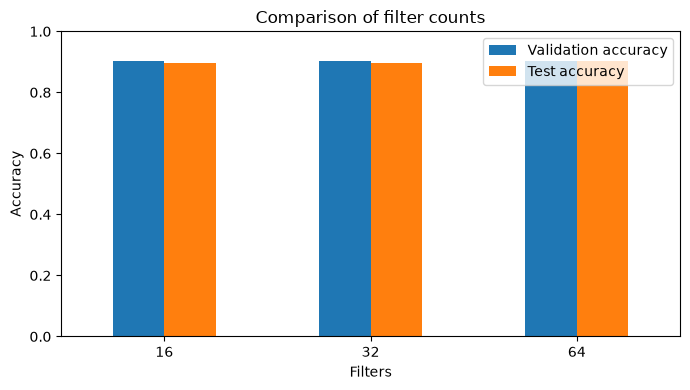

Best filter count: 64


In [13]:
filter_results.plot(
    x="Filters",
    y=["Validation accuracy", "Test accuracy"],
    kind="bar",
    figsize=(7, 4)
)

plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("Comparison of filter counts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Select using validation accuracy, not test accuracy
best_row = filter_results["Validation accuracy"].idxmax()
best_filters = int(filter_results.loc[best_row, "Filters"])

print("Best filter count:", best_filters)

In [16]:
# B. Test presence or absence of regularization
# Choose 16 filters for a simpler model even above figure show 64 !!! 

best_filters = 16

dropout_results = []

for dropout_rate in [0.0, 0.3]:

    # Start with a new model for each experiment
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)

    model = Sequential()
    model.add(Input(shape=(28, 28, 1)))
    model.add(
        Conv2D(best_filters, kernel_size=(3, 3), activation="relu")
    )
    model.add(MaxPooling2D(pool_size=(2, 2)))
    model.add(Flatten())
    model.add(Dense(64, activation="relu"))

    # Add dropout only in the regularization experiment
    if dropout_rate > 0:
        model.add(Dropout(dropout_rate))

    model.add(Dense(10, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["categorical_accuracy"]
    )

    print(f"\nTraining with dropout = {dropout_rate}")

    history = model.fit(
        X_train,
        y_train_onehot,
        epochs=8,
        batch_size=128,
        validation_split=0.2,
        verbose=2
    )

    test_loss, test_accuracy = model.evaluate(
        X_test, y_test_onehot, verbose=0
    )

    dropout_results.append({
        "Dropout": dropout_rate,
        "Validation accuracy": history.history[
            "val_categorical_accuracy"
        ][-1],
        "Test accuracy": test_accuracy,
        "Test loss": test_loss
    })

dropout_results = pd.DataFrame(dropout_results)
print(dropout_results.round(4))


Training with dropout = 0.0
Epoch 1/8
375/375 - 3s - 7ms/step - categorical_accuracy: 0.8195 - loss: 0.5230 - val_categorical_accuracy: 0.8683 - val_loss: 0.3799
Epoch 2/8
375/375 - 2s - 5ms/step - categorical_accuracy: 0.8790 - loss: 0.3461 - val_categorical_accuracy: 0.8850 - val_loss: 0.3276
Epoch 3/8
375/375 - 2s - 5ms/step - categorical_accuracy: 0.8931 - loss: 0.3014 - val_categorical_accuracy: 0.8900 - val_loss: 0.3042
Epoch 4/8
375/375 - 2s - 6ms/step - categorical_accuracy: 0.9024 - loss: 0.2730 - val_categorical_accuracy: 0.8961 - val_loss: 0.2883
Epoch 5/8
375/375 - 2s - 5ms/step - categorical_accuracy: 0.9104 - loss: 0.2514 - val_categorical_accuracy: 0.8991 - val_loss: 0.2787
Epoch 6/8
375/375 - 2s - 5ms/step - categorical_accuracy: 0.9162 - loss: 0.2332 - val_categorical_accuracy: 0.9014 - val_loss: 0.2718
Epoch 7/8
375/375 - 2s - 6ms/step - categorical_accuracy: 0.9215 - loss: 0.2173 - val_categorical_accuracy: 0.9009 - val_loss: 0.2710
Epoch 8/8
375/375 - 2s - 6ms/step

**Plot dropout results and select setting**

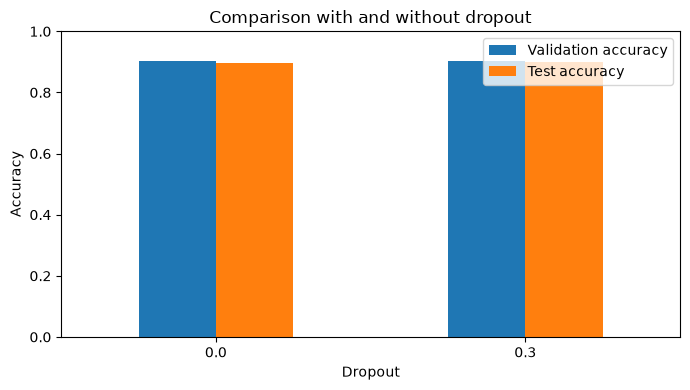

Selected filters: 16
Selected dropout: 0.3


In [17]:
dropout_results.plot(
    x="Dropout",
    y=["Validation accuracy", "Test accuracy"],
    kind="bar",
    figsize=(7, 4)
)

plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("Comparison with and without dropout")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

best_row = dropout_results["Validation accuracy"].idxmax()
best_dropout = float(dropout_results.loc[best_row, "Dropout"])

print("Selected filters:", best_filters)
print("Selected dropout:", best_dropout)

Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

**My Reflection:**
I used 16, 32, 64 filters. Their test accuracies were 89.53%, 89.56% and 90.20%, quite close. Instead of chooseing 64 which have more accuracies, I would perefer to choose 16 beacuse the trade-off (in term of time, quick model training) is better in 16, as very minimal gain if 64 selected or even 32. 

Final choice is 16 filters with dropout of 0.3. The 64 filter model with dropout achieved higher accuracy, but I preferred the smaller model for its faster training and similar performance. These differences are small, so I repeated the process and confirm the results.

# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

In [ ]:
import keras
from keras.models import Sequential
from keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
)

# fresh model
keras.backend.clear_session()
keras.utils.set_random_seed(42)

# final model using selected settings
final_model = Sequential()

final_model.add(Input(shape=(28, 28, 1)))
final_model.add(Conv2D(16, kernel_size=(3, 3), activation="relu"))
final_model.add(MaxPooling2D(pool_size=(2, 2)))
final_model.add(Flatten())
final_model.add(Dense(64, activation="relu"))
final_model.add(Dropout(0.3))
final_model.add(Dense(10, activation="softmax"))

# Compile the model
final_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["categorical_accuracy"]
)

# Train on full training set
final_history = final_model.fit(
    X_train,
    y_train_onehot,
    epochs=8,
    batch_size=128,
    verbose=2
)

# Evaluate on test set
final_loss, final_accuracy = final_model.evaluate(
    X_test,
    y_test_onehot,
    verbose=0
)

print(f"Final test accuracy: {final_accuracy:.2%}")
print(f"Final test loss: {final_loss:.4f}")

# Compare with earlier models
print(
    f"Change from baseline: "
    f"{(final_accuracy - baseline_accuracy) * 100:+.2f} percentage points"
)

print(
    f"Change from initial CNN: "
    f"{(final_accuracy - cnn_accuracy) * 100:+.2f} percentage points"
)

Epoch 1/8
469/469 - 3s - 6ms/step - categorical_accuracy: 0.7946 - loss: 0.5977
Epoch 2/8
469/469 - 2s - 5ms/step - categorical_accuracy: 0.8651 - loss: 0.3867
Epoch 3/8
469/469 - 2s - 5ms/step - categorical_accuracy: 0.8825 - loss: 0.3343
Epoch 4/8
469/469 - 2s - 5ms/step - categorical_accuracy: 0.8903 - loss: 0.3066
Epoch 5/8
469/469 - 2s - 5ms/step - categorical_accuracy: 0.8984 - loss: 0.2848
Epoch 6/8
469/469 - 3s - 6ms/step - categorical_accuracy: 0.9044 - loss: 0.2672
Epoch 7/8
469/469 - 2s - 5ms/step - categorical_accuracy: 0.9081 - loss: 0.2538
Epoch 8/8
469/469 - 2s - 5ms/step - categorical_accuracy: 0.9115 - loss: 0.2423
Final test accuracy: 90.37%
Final test loss: 0.2611
Change from baseline: +10.28 percentage points
Change from initial CNN: +0.50 percentage points


Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

**My Reflection**

My final model achieved a test accuracy of 90.37% and a test loss of 0.26. This was 10.28 percentage points higher than baseline model and 0.50 % points higher than the initial CNN.

I used 16 filters with dropout of 0.3 to balance accuracy and training time. The convolutional layer helped learn image patterns, while dropout may have reduced overfitting. Training on all 60,000 images instead of 48,000 may also have contributed to the final performance.

With more time, I would test different kernel sizes or add another convolutional layer, changing one setting at a time. I would also repeat the experiments with different random seeds to check whether the small improvements are consistent.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/09/2026`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.